---
**UNIVERSIDAD NACIONAL DE ASUNCIÓN**

**FACULTAD DE INGENIERÍA**

# **ROBOTICA I**

TRABAJO PRÁCTICO FINAL 2026S2

## **"Brazo robótico recolector de frutas"**

---
###**ESTACIÓN 4:** Sistema Autónomo de Recolección y Clasificación de Naranjas

**Grupo 4:**


*   Moisés Caballero
*   Leonardo Colina
*   Nicolás De Egea
*   Christian Pérez

**ENTREGA 6:** Control en Lazo Cerrado

**Fecha:** 04/10/2026

**Versión:** v1.0

# **1. Selección de Materiales**

## Motores
| Módulo / Subsistema | Componente / Equipo | Cantidad | Función |
| :--- | :--- | :---: | :--- |
| **Motores y Actuadores** | Metal DC Gearmotor 37Dx70.1L mm | 1 | Motor principal de alto torque |
| **Motores y Actuadores** | Metal DC Gearmotor 37Dx70.1L mm | 1 | Motor de rápida respuesta para muñeca |
| **Motores y Actuadores** | MOTOR NEMA 17 | 1 | Riel |
| **Motores y Actuadores** | MOTOR NEMA 17 | 1 | Transmisión secundaria de velocidad media |
| **Motores y Actuadores** | MG995 Servo Motor | 1 | Torsión |
| **Motores y Actuadores** | MG995 Servo Motor | 1 | Muñeca |

## Drivers y Placas de Control
| Módulo / Subsistema | Componente / Equipo | Cantidad | Función |
| :--- | :--- | :---: | :--- |
| **Sistema de Control y Potencia** | Arduino MEGA 2560 | 1 | Controlador Principal para RRP |
| **Sistema de Control y Potencia** | RAMPS 1.4 3D Printer Shield | 1 | Shield montado sobre Arduino MEGA |
| **Sistema de Control y Potencia** | ProtoScrew Shield para Arduino | 1 | Placa de borneras para cableado |
| **Sistema de Control y Potencia** | TB6600 Stepper Motor Driver (5A) | 1 | Driver de potencia para articulación principal |
| **Sistema de Control y Potencia** | Driver Sabertooth | 1 | Motor 1ra Articulación |

## Sensores
| Módulo / Subsistema | Componente / Equipo | Cantidad | Función |
| :--- | :--- | :---: | :--- |
| **Sensado y Acople** | Camara | 2 | Detección |
| **Sensado y Acople** | MPS20N0040D | 1 | Sensor de Presión |
| **Sensado y Acople** | Final de Carrera | 3 | Homing |

# **2. Control de Lazo Abierto**

# **3. Control de Lazo Cerrado**

Para la implementación del control de lazo cerrado de posición y velocidad, se toma como referencia el **Metal DC Gearmotor 37Dx70.1L mm** equipado con reductora y quadrature encoder.

---

### 3.1. Ecuaciones Electromecánicas del Motor DC

El comportamiento dinámico del motor DC se rige por la interacción de sus subsistemas eléctrico y mecánico:

1. **Ecuación del Circuito Eléctrico (Malla de Armadura):**
   $$v(t) = R \cdot i(t) + L \frac{di(t)}{dt} + e_b(t)$$

2. **Fuerza Contraelectromotriz (f.c.e.m.):**
   $$e_b(t) = K_e \cdot \omega(t) = K_e \frac{d\theta(t)}{dt}$$

3. **Ecuación del Balance Mecánico (Eje de Rotación):**
   $$J \frac{d\omega(t)}{dt} + b \cdot \omega(t) = \tau_m(t) - \tau_L(t)$$

4. **Torque Electromagnético Generado:**
   $$\tau_m(t) = K_t \cdot i(t)$$

*Donde:*
* $v(t)$: Tensión aplicada a la armadura ($\text{V}$).
* $i(t)$: Corriente de armadura ($\text{A}$).
* $R, L$: Resistencia ($\Omega$) e inductancia ($\text{H}$) del devanado.
* $e_b(t)$: Tensión contraelectromotriz ($\text{V}$).
* $K_e, K_t$: Constante eléctrica ($\text{V}\cdot\text{s/rad}$) y constante de torque ($\text{N}\cdot\text{m/A}$).
* $J$: Momento de inercia del rotor y reductora ($\text{kg}\cdot\text{m}^2$).
* $b$: Coeficiente de fricción viscosa ($\text{N}\cdot\text{m}\cdot\text{s/rad}$).
* $\theta(t), \omega(t)$: Posición angular ($\text{rad}$) y velocidad angular ($\text{rad/s}$).

---

### 3.2. Función de Transferencia $G(s)$

Aplicando la Transformada de Laplace con condiciones iniciales nulas y considerando la inductancia $L \approx 0$ (frecuente en motores DC pequeños de imán permanente):

$$\frac{\Theta(s)}{V(s)} = G(s) = \frac{K}{s(\tau s + 1)}$$

*Donde:*
* $K = \frac{K_t}{R \cdot b + K_t \cdot K_e}$: Ganancia del sistema en estado estacionario.
* $\tau = \frac{R \cdot J}{R \cdot b + K_t \cdot K_e}$: Constante de tiempo mecánica del motor.

---

### 3.3. Modelo del Controlador PID

#### Dominio Continuo:
El controlador ajusta el voltaje de salida $u(t)$ en función del error de posición $e(t) = r(t) - \theta(t)$:

$$u(t) = K_p e(t) + K_i \int_{0}^{t} e(\tau) d\tau + K_d \frac{de(t)}{dt}$$

#### Dominio Discreto (Para implementación en Arduino/Microcontrolador):
Utilizando la aproximación de Euler hacia atrás (*Backward Euler*) con un tiempo de muestreo $T_s$:

$$u[k] = K_p e[k] + K_i T_s \sum_{j=0}^{k} e[j] + \frac{K_d}{T_s} \big(e[k] - e[k-1]\big)$$

*Donde $e[k] = \theta_{ref}[k] - \theta_{real}[k]$ es el error en la muestra actual.*

---

### 3.4. Simulación de Posición

> Add blockquote



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 578.3/578.3 kB 10.9 MB/s eta 0:00:00


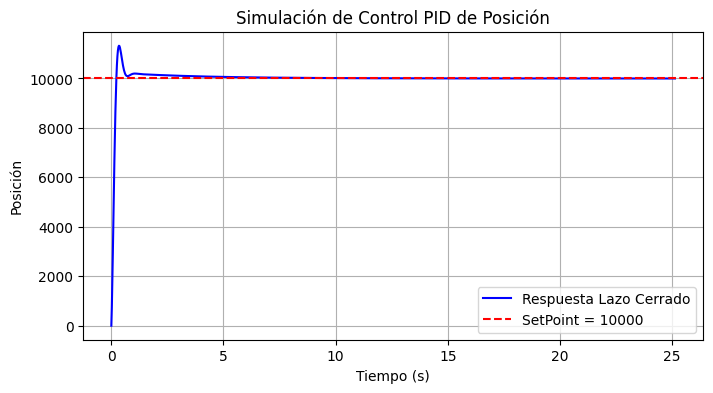

In [ ]:
!pip install control

import numpy as np
import matplotlib.pyplot as plt
import control as ct

# 1. Definir el modelo del motor DC
K = 2.5       # Ganancia de velocidad/voltaje
tau = 0.1     # Constante de tiempo

G = ct.tf([K], [tau, 1, 0])
# G(s) = K / (tau*s^2 + s)

# 2. Definir el Controlador PID
Kp, Ki, Kd = 4.5, 1.2, 0.1

C = ct.tf([Kd, Kp, Ki], [1, 0])
# C(s) = (Kd*s^2 + Kp*s + Ki) / s

# 3. Lazo cerrado
Lazo_Cerrado = ct.feedback(C * G, 1)

# 4. Setpoint
setpoint = 10000

# 5. Respuesta al escalón unitario
t, y = ct.step_response(Lazo_Cerrado)

# Escalar la respuesta para que el escalón sea de 0 a 10000
y = y * setpoint

# 6. Graficar
plt.figure(figsize=(8, 4))

plt.plot(
    t,
    y,
    label='Respuesta Lazo Cerrado',
    color='b'
)

plt.axhline(
    setpoint,
    color='r',
    linestyle='--',
    label='SetPoint = 10000'
)

plt.title('Simulación de Control PID de Posición')
plt.xlabel('Tiempo (s)')
plt.ylabel('Posición')
plt.grid(True)
plt.legend()

plt.show()

### 3.5. Simulación de Velocidad

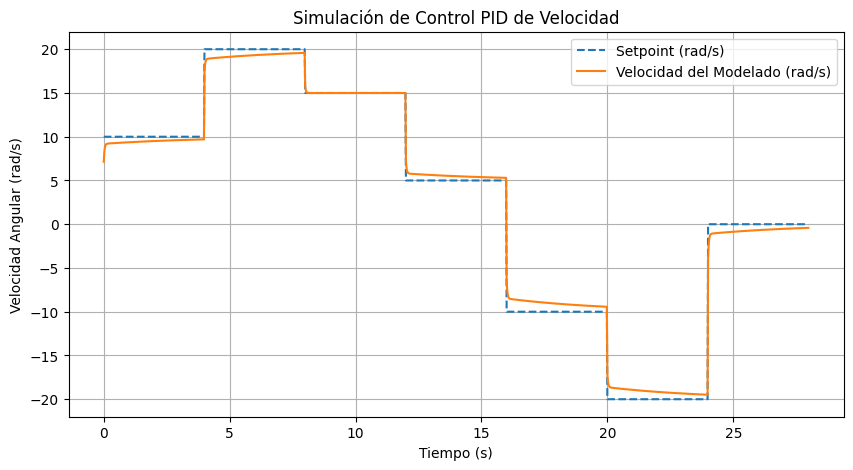

In [ ]:
!pip install control

import numpy as np
import matplotlib.pyplot as plt
import control as ct

# ============================================================
# 1. MODELO DEL MOTOR DC - CONTROL DE VELOCIDAD
# ============================================================

K = 2.5       # Ganancia del motor
tau = 0.1     # Constante de tiempo [s]

# Modelo simplificado de velocidad:
#
#             K
# G(s) = -----------
#          tau*s + 1
#
G = ct.tf([K], [tau, 1])


# ============================================================
# 2. CONTROLADOR PID
# ============================================================

Kp = 4.5
Ki = 1.2
Kd = 0.1

# C(s) = Kd*s + Kp + Ki/s
C = ct.tf([Kd, Kp, Ki], [1, 0])


# ============================================================
# 3. LAZO CERRADO
# ============================================================

Lazo_Cerrado = ct.feedback(C * G, 1)


# ============================================================
# 4. SECUENCIA DE SETPOINTS
# ============================================================

SETPOINT_SEQUENCE = [10, 20, 15, 5, -10, -20, 0]

STEP_DURATION_S = 4       # Cada setpoint dura 4 segundos


# ============================================================
# 5. TIEMPO TOTAL DE SIMULACION
# ============================================================

total_time = len(SETPOINT_SEQUENCE) * STEP_DURATION_S

# Paso de simulación de 20 ms,
# igual al Ts indicado en tu MATLAB
Ts = 0.02

t = np.arange(0, total_time, Ts)


# ============================================================
# 6. CONSTRUIR LA REFERENCIA
# ============================================================

setpoint = np.zeros_like(t)

for i, sp in enumerate(SETPOINT_SEQUENCE):

    start_time = i * STEP_DURATION_S
    end_time = (i + 1) * STEP_DURATION_S

    mask = (t >= start_time) & (t < end_time)

    setpoint[mask] = sp


# ============================================================
# 7. SIMULAR EL SISTEMA
# ============================================================

# Simulación de la respuesta para una entrada arbitraria
t_out, y, x = ct.forced_response(
    Lazo_Cerrado,
    T=t,
    U=setpoint,
    return_x=True
)


# ============================================================
# 8. GRAFICA
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    t,
    setpoint,
    linestyle='--',
    label='Setpoint (rad/s)'
)

plt.plot(
    t_out,
    y,
    label='Velocidad del Modelado (rad/s)'
)

plt.xlabel('Tiempo (s)')
plt.ylabel('Velocidad Angular (rad/s)')

plt.title(
    'Simulación de Control PID de Velocidad'
)

plt.grid(True)
plt.legend()

plt.show()

# **4. Implementación**

### 4.1. Montaje de Hardware

Ambos controladores se implementaron sobre el motor DC con reductora y *quadrature encoder*, accionado mediante un puente H **L298N** y controlado por un **Arduino Uno** (ATmega328P, lógica 5 V). Se comparte el mismo conexionado:

| Señal | Pin Arduino | Tipo | Función |
| :--- | :---: | :--- | :--- |
| `ENC_A` | 2 | Entrada con *pull-up* interno, interrupción externa | Canal A del encoder |
| `ENC_B` | 3 | Entrada con *pull-up* interno, interrupción externa | Canal B del encoder |
| `ENA` | 9 | Salida PWM (~490 Hz) | Ciclo de trabajo del L298N |
| `IN1` | 8 | Salida digital | Sentido de giro |
| `IN2` | 7 | Salida digital | Sentido de giro |

| Controlador | Placa | Decodificación del encoder |
| :--- | :--- | :--- |
| PID de posición | Arduino Uno (ATmega328P) | Interrupción solo en el canal A |
| PI de velocidad | Arduino Uno (ATmega328P) | x4 (interrupciones en A y B) |

### 4.2. Arquitectura del Firmware

Los dos controladores siguen la misma estructura, sin bloqueos (`delay()`) dentro del `loop()`:

1. **ISR del encoder:** actualiza el contador de pulsos `pulse_count` en cada flanco, de forma asíncrona al lazo de control.
2. **Interfaz serial:** recibe el *setpoint* (grados para posición, rad/s para velocidad).
3. **Temporización:** el controlador se ejecuta cada $T_s$ comparando `millis()` / `micros()` con el instante de la última ejecución.
4. **Medición:** copia atómica del contador (`noInterrupts()` / `interrupts()`) y conversión a $\theta$ [rad] o $\omega$ [rad/s].
5. **Ley de control:** cálculo de $e[k]$ y de la señal $u[k]$.
6. **Saturación y anti-windup:** limitación de $u[k]$ al rango del PWM $[0, 255]$ y protección del integrador.
7. **Actuación:** sentido de giro con `IN1`/`IN2` y magnitud con `analogWrite(ENA, pwm)`.
8. **Telemetría:** envío de la trama CSV `setpoint,medida,pwm` hacia MATLAB.

### 4.3. Resolución del Encoder

La cantidad de conteos por vuelta del eje de salida es:

$$
CPR = PPR \cdot m \cdot N
$$

donde $PPR$ son los pulsos por vuelta del eje del motor, $m$ el factor de decodificación y $N$ la relación de reducción. La resolución angular resulta:

$$
\Delta\theta = \frac{2\pi}{CPR}
$$

Para el control de velocidad ($PPR = 11$, $m = 4$, $N = 12$):

$$
\begin{aligned}
CPR &= 11 \cdot 4 \cdot 12 = 528 \ \text{counts/rev} \\
\Delta\theta &= \frac{360^\circ}{528} \approx 0.68^\circ
\end{aligned}
$$

En el control de posición se utiliza `TOTAL_CPR = 132` ($11 \cdot 12$).

### 4.4. Período de Muestreo

**Posición ($T_s = 10\ \text{ms}$):** con la constante de tiempo del modelo $\tau \approx 0.1\ \text{s}$:

$$
\frac{\tau}{T_s} = \frac{0.1}{0.01} = 10
$$

Se obtienen 10 muestras dentro de la constante de tiempo, suficiente para que la discretización no degrade la respuesta del lazo.

**Velocidad ($T_s = 20\ \text{ms}$):** la velocidad se estima contando pulsos en una ventana de duración $T_s$, por lo que la mínima velocidad distinguible es:

$$
\Delta\omega_{min} = \frac{2\pi}{CPR \cdot T_s}
$$

| $T_s$ | $\Delta\omega_{min}$ |
| :---: | :---: |
| 10 ms | $\frac{2\pi}{528 \cdot 0.01} \approx 1.19\ \text{rad/s}$ |
| 20 ms | $\frac{2\pi}{528 \cdot 0.02} \approx 0.60\ \text{rad/s}$ |

Se eligió 20 ms como compromiso entre menor ruido de cuantización en la medición y ancho de banda del lazo ($\tau / T_s = 5$). Además, se usa el $\Delta t$ real medido con `micros()` para eliminar el *jitter* del período.

### 4.5. Controlador PID de Posición

Ley de control discreta (*Backward Euler*), con $T_s = 10\ \text{ms}$:

$$
\begin{aligned}
\theta[k] &= \frac{N_{pulsos}[k]}{CPR}\cdot 2\pi \\
e[k] &= \theta_{ref} - \theta[k] \\
I[k] &= I[k-1] + e[k]\,T_s \\
u[k] &= K_p\,e[k] + K_i\,I[k] + \frac{K_d}{T_s}\big(e[k]-e[k-1]\big)
\end{aligned}
$$

El signo de $u[k]$ define el sentido de giro y $|u[k]|$ el ciclo de trabajo del PWM.

| Parámetro | Valor | Descripción |
| :--- | :---: | :--- |
| $K_p$ | 1.0843 | Ganancia proporcional |
| $K_i$ | 2.5465 | Ganancia integral |
| $K_d$ | 0 | Sin acción derivativa (el PID Tuner entregó un PI) |
| $T_s$ | 10 ms | Período de muestreo |
| *Deadband* | PWM < 30 | Por debajo, el motor se apaga |

```cpp
/*
 * Controlador PID de posición en lazo cerrado
 * Plataforma: Arduino Uno (ATmega328P) + L298N
 * Entrada serial: ángulo deseado en grados
 * Salida serial (CSV): setpoint_rad,posicion_rad,pwm
 */

#include <Arduino.h>

// Pines
const int ENC_A = 2;   // Interrupción externa
const int ENC_B = 3;
const int ENA   = 9;   // PWM
const int IN1   = 8;
const int IN2   = 7;

// Parámetros del sistema
const float TOTAL_CPR     = 132.0;  // 11 PPR x 12 (reductora)
const float SAMPLE_TIME_S = 0.01;   // Ts = 10 ms

// Ganancias (PID Tuner de MATLAB, sin acción derivativa)
float kp = 1.0843;
float ki = 2.5465;
float kd = 0.0;

// Estado del controlador
float error_integral = 0.0;
float previous_error = 0.0;
float setpoint_rad   = 0.0;
bool  motor_enabled  = false;   // El motor arranca apagado hasta recibir un comando

volatile long pulse_count   = 0;
unsigned long previous_time = 0;

// ISR del encoder: el sentido de giro se obtiene comparando A y B
void readEncoder() {
  int aVal = digitalRead(ENC_A);
  int bVal = digitalRead(ENC_B);
  if (aVal == bVal) {
    pulse_count++;
  } else {
    pulse_count--;
  }
}

void setup() {
  Serial.begin(115200);
  Serial.println("\n--- SISTEMA PID INICIADO ---");
  Serial.println("El motor esta apagado. Envia un angulo en GRADOS (ej: 90, -45, 180)");
  Serial.println("por el monitor serial para establecer el setpoint y arrancar.");

  pinMode(ENC_A, INPUT_PULLUP);
  pinMode(ENC_B, INPUT_PULLUP);
  attachInterrupt(digitalPinToInterrupt(ENC_A), readEncoder, CHANGE);

  pinMode(IN1, OUTPUT);
  pinMode(IN2, OUTPUT);
  pinMode(ENA, OUTPUT);

  previous_time = millis();
}

// dir: 1 = adelante, -1 = atrás, 0 = parado
void setMotor(int dir, int pwm_val) {
  if (dir == 1) {
    digitalWrite(IN1, HIGH);
    digitalWrite(IN2, LOW);
  } else if (dir == -1) {
    digitalWrite(IN1, LOW);
    digitalWrite(IN2, HIGH);
  } else {
    digitalWrite(IN1, LOW);
    digitalWrite(IN2, LOW);
  }
  analogWrite(ENA, pwm_val);
}

void loop() {
  // 1. Lectura del setpoint por serial
  if (Serial.available() > 0) {
    float input_degrees = Serial.parseFloat();
    while (Serial.available() > 0) {
      Serial.read();   // Descartar \r y \n
    }

    if (input_degrees != 0.0 || (input_degrees == 0.0 && Serial.available() == 0)) {
      setpoint_rad  = input_degrees * (PI / 180.0);
      motor_enabled = true;

      Serial.print("\n>>> NUEVO SETPOINT: ");
      Serial.print(input_degrees);
      Serial.println(" grados. Arrancando motor...");
    }
  }

  // 2. Ejecución periódica del controlador cada Ts
  unsigned long current_time = millis();

  if (current_time - previous_time >= (SAMPLE_TIME_S * 1000.0)) {

    // Lectura atómica del contador
    noInterrupts();
    long current_pulses = pulse_count;
    interrupts();

    float current_position_rad = (current_pulses / TOTAL_CPR) * (2.0 * PI);
    float error = setpoint_rad - current_position_rad;

    // 3. Ley de control PID discreta
    float proportional = kp * error;

    error_integral += error * SAMPLE_TIME_S;
    float integral = ki * error_integral;

    float derivative = kd * (error - previous_error) / SAMPLE_TIME_S;

    float control_signal = proportional + integral + derivative;

    // 4. Sentido de giro según el signo de u
    int dir = 1;
    if (control_signal < 0) {
      dir = -1;
      control_signal = -control_signal;
    }

    // 5. Saturación + anti-windup (clamping)
    int pwm_val = (int)control_signal;
    if (pwm_val > 255) {
      pwm_val = 255;
      error_integral -= error * SAMPLE_TIME_S;   // No integrar estando saturado
    }

    // 6. Deadband: evita zumbido y calentamiento del L298N con PWM bajo
    if (pwm_val < 30) {
      pwm_val = 0;
      dir = 0;
    }

    if (!motor_enabled) {
      pwm_val = 0;
      dir = 0;
      error_integral = 0.0;
    }

    setMotor(dir, pwm_val);

    // 7. Telemetría CSV
    if (motor_enabled) {
      Serial.print(setpoint_rad);
      Serial.print(",");
      Serial.print(current_position_rad);
      Serial.print(",");
      Serial.println(pwm_val);
    }

    previous_error = error;
    previous_time  = current_time;
  }
}
```

**Funcionamiento:**
- `readEncoder()`: en cada flanco del canal A compara A con B; si son iguales el giro es positivo, si no, negativo.
- `setMotor()`: traduce el sentido (`dir`) y la magnitud (`pwm_val`) a las entradas del L298N.
- `loop()`, interfaz serial: convierte el ángulo recibido a radianes y habilita el motor.
- `loop()`, bloque periódico: lee el encoder, calcula los tres términos del PID, aplica saturación con anti-windup y *deadband*, acciona el motor y envía la telemetría.

### 4.6. Controlador PI de Velocidad

La velocidad se estima por diferencia de conteos en cada período y se filtra con un promedio móvil exponencial (EWMA):

$$
\begin{aligned}
\omega_{raw}[k] &= \frac{N[k]-N[k-1]}{CPR}\cdot\frac{2\pi}{\Delta t_k} \\
\hat{\omega}[k] &= \alpha\,\omega_{raw}[k] + (1-\alpha)\,\hat{\omega}[k-1]
\end{aligned}
$$

El PI trabaja sobre magnitudes; el sentido de giro lo fija el signo del *setpoint*, de modo que el controlador nunca invierte el puente H bruscamente:

$$
\begin{aligned}
e[k] &= |\omega_{ref}| - \hat{\omega}[k]\cdot\text{sign}(\omega_{ref}) \\
I[k] &= I[k-1] + e[k]\,\Delta t_k \quad \text{(solo si no hay saturación)} \\
u[k] &= u_0 + K_p\,e[k] + K_i\,I[k]
\end{aligned}
$$

donde $u_0$ es un término *feedforward* que compensa la fricción estática del motor.

| Parámetro | Valor | Descripción |
| :--- | :---: | :--- |
| $K_p$ | 3.0 | PWM / (rad/s) |
| $K_i$ | 15.0 | PWM / rad |
| $u_0$ | 30 | PWM mínimo para vencer la fricción estática |
| $\alpha$ | 0.5 | Coeficiente del filtro EWMA |
| $T_s$ | 20 ms | Período de control |
| $CPR$ | 528 | Decodificación x4 |

```cpp
/*
 * Controlador PI de velocidad en lazo cerrado
 * Plataforma: Arduino Uno (ATmega328P) + L298N
 * Entrada serial: velocidad deseada en rad/s ("0" detiene el motor)
 * Salida serial (CSV): setpoint,velocidad_filtrada,pwm
 */

#include <Arduino.h>

// Pines
const uint8_t ENC_A = 2;   // INT0 (PD2)
const uint8_t ENC_B = 3;   // INT1 (PD3)
const uint8_t ENA   = 9;   // PWM
const uint8_t IN1   = 8;
const uint8_t IN2   = 7;

// Encoder
const float ENCODER_PPR = 11.0;
const float GEAR_RATIO  = 12.0;
const float DECODE_MULT = 4.0;   // Decodificación x4
const float TOTAL_CPR   = ENCODER_PPR * GEAR_RATIO * DECODE_MULT;   // 528 counts/rev

const unsigned long CONTROL_PERIOD_US = 20000UL;   // Ts = 20 ms

// Ganancias del controlador
float kp = 3.0;    // PWM / (rad/s)
float ki = 15.0;   // PWM / rad

const float PWM_FRICTION = 30.0;   // Feedforward de fricción estática
const int   PWM_MAX      = 255;
const float ALPHA        = 0.5;    // Filtro EWMA de la velocidad

// Estado
volatile long    pulse_count = 0;
volatile uint8_t enc_state   = 0;

long          previous_pulses  = 0;
unsigned long previous_time_us = 0;
float         filtered_vel     = 0.0;   // rad/s
float         error_integral   = 0.0;   // rad
float         setpoint_rad_s   = 0.0;   // rad/s
bool          motor_enabled    = false;

// Tabla de decodificación x4: índice = (estado_anterior << 2) | estado_nuevo
// Las transiciones inválidas suman 0
const int8_t QEM[16] = {
   0, +1, -1,  0,
  -1,  0,  0, +1,
  +1,  0,  0, -1,
   0, -1, +1,  0
};

// ISR común para A y B (lectura directa del puerto D del ATmega328P)
void encoderISR() {
  uint8_t pins = PIND;
  uint8_t a = (pins >> 2) & 0x01;
  uint8_t b = (pins >> 3) & 0x01;
  uint8_t new_state = (a << 1) | b;
  pulse_count += QEM[(enc_state << 2) | new_state];
  enc_state = new_state;
}

// dir: 1 = adelante, -1 = atrás, 0 = parado
void setMotor(int dir, int pwm_val) {
  if (dir == 1) {
    digitalWrite(IN1, HIGH);
    digitalWrite(IN2, LOW);
  } else if (dir == -1) {
    digitalWrite(IN1, LOW);
    digitalWrite(IN2, HIGH);
  } else {
    digitalWrite(IN1, LOW);
    digitalWrite(IN2, LOW);
    pwm_val = 0;
  }
  analogWrite(ENA, pwm_val);
}

void resetController() {
  error_integral = 0.0;
  filtered_vel   = 0.0;
}

void setup() {
  Serial.begin(115200);

  pinMode(ENC_A, INPUT_PULLUP);
  pinMode(ENC_B, INPUT_PULLUP);
  enc_state = (digitalRead(ENC_A) << 1) | digitalRead(ENC_B);
  attachInterrupt(digitalPinToInterrupt(ENC_A), encoderISR, CHANGE);
  attachInterrupt(digitalPinToInterrupt(ENC_B), encoderISR, CHANGE);

  pinMode(IN1, OUTPUT);
  pinMode(IN2, OUTPUT);
  pinMode(ENA, OUTPUT);
  setMotor(0, 0);

  previous_time_us = micros();
}

void loop() {
  // 1. Lectura del setpoint por serial
  if (Serial.available() > 0) {
    float new_sp = Serial.parseFloat();
    while (Serial.available() > 0) Serial.read();

    // Reiniciar el PI si cambia el sentido de giro o se detiene
    if ((new_sp > 0) != (setpoint_rad_s > 0) || new_sp == 0.0) {
      resetController();
    }
    setpoint_rad_s = new_sp;
    motor_enabled  = (new_sp != 0.0);
  }

  // 2. Ejecución periódica con dt real
  unsigned long now_us = micros();
  unsigned long dt_us  = now_us - previous_time_us;
  if (dt_us < CONTROL_PERIOD_US) return;

  float dt = dt_us * 1.0e-6;
  previous_time_us = now_us;

  // 3. Medición de velocidad
  noInterrupts();
  long current_pulses = pulse_count;
  interrupts();

  long delta_pulses = current_pulses - previous_pulses;
  previous_pulses   = current_pulses;

  float raw_vel = ((float)delta_pulses / TOTAL_CPR) * TWO_PI / dt;   // rad/s
  filtered_vel  = ALPHA * raw_vel + (1.0 - ALPHA) * filtered_vel;

  if (!motor_enabled) {
    setMotor(0, 0);
    return;
  }

  // 4. PI sobre magnitudes: el sentido lo fija el signo del setpoint
  int   dir     = (setpoint_rad_s > 0) ? 1 : -1;
  float sp_mag  = fabs(setpoint_rad_s);
  float vel_mag = filtered_vel * dir;
  float error   = sp_mag - vel_mag;

  float u = PWM_FRICTION + kp * error + ki * error_integral;

  // 5. Anti-windup por integración condicional
  bool sat_high = (u >= PWM_MAX) && (error > 0);
  bool sat_low  = (u <= 0)       && (error < 0);
  if (!sat_high && !sat_low) {
    error_integral += error * dt;
    u = PWM_FRICTION + kp * error + ki * error_integral;
  }

  // 6. Saturación al rango del PWM
  if (u > PWM_MAX) u = PWM_MAX;
  if (u < 0)       u = 0;
  int pwm_val = (int)(u + 0.5);

  setMotor(dir, pwm_val);

  // 7. Telemetría CSV
  Serial.print(setpoint_rad_s);
  Serial.print(',');
  Serial.print(filtered_vel);
  Serial.print(',');
  Serial.println(pwm_val);
}
```

**Funcionamiento:**
- `encoderISR()`: se ejecuta ante cualquier flanco de A o B. Lee el puerto D directamente (más rápido que `digitalRead()`) y usa la tabla `QEM` para sumar $+1$, $-1$ o $0$ según la transición de estado.
- `resetController()`: reinicia el integrador y el filtro al detener el motor o cambiar de sentido.
- `loop()`, interfaz serial: recibe el *setpoint* en rad/s; `0` detiene el motor.
- `loop()`, bloque periódico: mide $\Delta t$ real, estima y filtra la velocidad, calcula el PI con integración condicional, satura la salida y envía la telemetría.

### 4.7. Mecanismos Anti-windup

Cuando el PWM satura en 255, el integrador seguiría acumulando error y provocaría un *overshoot* grande al salir de la saturación. Cada controlador utiliza una estrategia distinta:

| Controlador | Estrategia | Implementación | Comportamiento |
| :--- | :--- | :--- | :--- |
| Posición | *Clamping* | Si $\lvert u \rvert > 255$, se deshace la última integración | Simple; el integrador se congela mientras haya saturación |
| Velocidad | Integración condicional | Solo se integra si no hay saturación, o si el error ayuda a salir de ella | Más preciso: permite descargar el integrador estando saturado |

### 4.8. Adquisición de Datos (Hardware-in-the-Loop)

Los datos se capturan en MATLAB mediante un *callback* que se ejecuta al recibir cada trama CSV del Arduino, graficando en tiempo real el *setpoint*, la variable medida y la señal de control.

**Control de posición:** envía un único escalón de *setpoint*.

```matlab
% -------------------------------------------------------------------------
% DATA ACQUISITION SCRIPT - HARDWARE IN THE LOOP (HIL)
% Proyecto: Robot Recolector de Naranjas - Robótica 1
% -------------------------------------------------------------------------
clear all; close all; clc;
% 'clear all' destruye cualquier objeto 'serialport' en el workspace, cerrando el COM3.

% 1. PARAMETROS DE HARDWARE Y ENLACE SERIAL
% -------------------------------------------------------------------------
port = "COM3";
baudRate = 115200;

disp(">>> Inicializando conexion asincrona con " + port + "...");
s = serialport(port, baudRate);
% El 'Terminator' indica el final de la trama de datos (coincide con Serial.println)
configureTerminator(s, "LF"); 

% 2. CONFIGURACION DE LA INTERFAZ GRAFICA (GUI)
% -------------------------------------------------------------------------
fig = figure('Name', 'Analisis de Respuesta Transitoria PID', 'NumberTitle', 'off');

% Eje Y Primario (Posicion Angular)
yyaxis left;
line_setpoint = animatedline('Color', 'r', 'LineStyle', '--', 'LineWidth', 1.5, 'DisplayName', 'Setpoint (rad)');
line_pos = animatedline('Color', 'b', 'LineWidth', 2, 'DisplayName', 'Posicion Real (rad)');
ylabel('Posicion Angular (Radianes)');
grid on;

% Eje Y Secundario (Senal de Control - PWM / Saturation)
yyaxis right;
line_pwm = animatedline('Color', 'k', 'LineStyle', ':', 'LineWidth', 1, 'DisplayName', 'PWM (0-255)');
ylabel('Senal de Control (PWM)');
ylim([0 300]); % Dejamos margen por encima de los 255 del duty cycle maximo

xlabel('Muestras');
title('Hardware-in-the-Loop: Step Response del Motor DC');
legend('Location', 'best');

% Guardamos los punteros a las lineas y el contador de muestras en el objeto figure
% para evitar el uso de variables globales, lo cual es mala practica en MATLAB.
userData = struct('line_setpoint', line_setpoint, 'line_pos', line_pos, 'line_pwm', line_pwm, 'sample_count', 0);
fig.UserData = userData;

% 3. CONFIGURACION DEL CALLBACK (INTERRUPCION POR SOFTWARE)
% -------------------------------------------------------------------------
% La funcion 'readSerialCallback' se ejecutara solo cuando llegue un "\n"
configureCallback(s, "terminator", @(src, event) readSerialCallback(src, event, fig));

% BUGFIX CRITICO: Hardware Reset del Arduino Uno.
% Al abrir el puerto COM, la senal DTR provoca el reinicio del ATmega328P.
% Si enviamos el comando inmediatamente, el bootloader lo ignora.
disp(">>> Esperando 2.5 segundos para que el Arduino Uno termine de bootear...");
pause(2.5);

disp(">>> Enlace establecido. Enviando Setpoint de prueba...");

% 4. ACTUACION: ENVIO DE COMANDO AL CONTROLADOR
% -------------------------------------------------------------------------
% Mandamos el setpoint para encender la maquina de estados del motor
writeline(s, "10000"); 


% -------------------------------------------------------------------------
% FUNCION DE SERVICIO DE INTERRUPCION (ISR DEL PUERTO SERIAL)
% -------------------------------------------------------------------------
function readSerialCallback(src, ~, fig)
    % 1. Extraer la trama de datos del buffer
    rawData = readline(src);
    
    % 2. Parsing: Separar el CSV y convertir a double
    data = str2double(split(rawData, ','));
    
    % 3. Filtrado de ruido: La cadena de inicio del Arduino dice "SISTEMA INICIADO".
    % Al pasarle str2double se vuelve NaN. Solo graficamos si llegaron los 3 datos limpios.
    if length(data) == 3 && all(~isnan(data))
        
        % Seguridad: Si el usuario cerro la ventana grafica, detener el script
        if ~isvalid(fig)
            configureCallback(src, "off");
            disp(">>> Graficador cerrado. Recepcion detenida.");
            return;
        end
        
        % Recuperar los handles graficos y actualizar contador
        handles = fig.UserData;
        handles.sample_count = handles.sample_count + 1;
        t = handles.sample_count;
        
        % Inyectar la posicion X (muestras) e Y (magnitud) al frame grafico
        addpoints(handles.line_setpoint, t, data(1));
        addpoints(handles.line_pos, t, data(2));
        addpoints(handles.line_pwm, t, data(3));
        
        fig.UserData = handles;
        
        % Forzar el renderizado de la GPU minimizando el overhead del sistema
        drawnow limitrate;
    end
end
```

**Control de velocidad:** un `timer` envía una secuencia de escalones (incluye inversión de giro) mientras el *callback* serial grafica la respuesta. Al cerrar la ventana se envía `0` para detener el motor.

```matlab
% -------------------------------------------------------------------------
% DATA ACQUISITION SCRIPT - VELOCITY CONTROL (HIL)
% Proyecto: Robot Recolector de Naranjas - Robótica 1
% -------------------------------------------------------------------------
clear all; close all; clc;
% 'clear all' NO borra timers: se eliminan los que hayan quedado de corridas anteriores
delete(timerfindall);

% 1. PARAMETROS DE HARDWARE Y ENLACE SERIAL
% -------------------------------------------------------------------------
port = "COM3";
baudRate = 115200;

% 1b. PERFIL DE REFERENCIA (secuencia de escalones de velocidad)
% -------------------------------------------------------------------------
% Cada valor se mantiene durante STEP_DURATION_S segundos.
% El ultimo valor deberia ser 0 para que el motor termine detenido.
SETPOINT_SEQUENCE = [10 20 15 5 -10 -20 0];   % rad/s
STEP_DURATION_S   = 4;                          % s por escalon
REPEAT_SEQUENCE   = false;                      % true = repetir en bucle (ignora el 0 final hasta cerrar la ventana)

disp(">>> Inicializando conexion asincrona con " + port + " para Control de Velocidad...");
s = serialport(port, baudRate);
configureTerminator(s, "LF"); 

% 2. CONFIGURACION DE LA INTERFAZ GRAFICA (GUI)
% -------------------------------------------------------------------------
fig = figure('Name', 'Analisis de Respuesta Transitoria PID (Velocidad)', 'NumberTitle', 'off');

% Eje Y Primario (Velocidad Angular)
yyaxis left;
line_setpoint = animatedline('Color', 'r', 'LineStyle', '--', 'LineWidth', 1.5, 'DisplayName', 'Setpoint (rad/s)');
line_vel = animatedline('Color', 'b', 'LineWidth', 2, 'DisplayName', 'Velocidad Real (rad/s)');
ylabel('Velocidad Angular (rad/s)');
grid on;

% Eje Y Secundario (Senal de Control - PWM)
yyaxis right;
line_pwm = animatedline('Color', 'k', 'LineStyle', ':', 'LineWidth', 1, 'DisplayName', 'PWM (0-255)');
ylabel('Senal de Control (PWM)');
ylim([0 300]); 

xlabel('Muestras (Ts = 20 ms)');
title('Hardware-in-the-Loop: Step Response del Motor DC (Velocidad)');
legend('Location', 'best');

% Estructura de punteros para el callback
userData = struct('line_setpoint', line_setpoint, 'line_vel', line_vel, 'line_pwm', line_pwm, 'sample_count', 0);
fig.UserData = userData;

% 3. CONFIGURACION DEL CALLBACK (INTERRUPCION POR SOFTWARE)
% -------------------------------------------------------------------------
configureCallback(s, "terminator", @(src, event) readSerialCallback(src, event, fig));

% BUGFIX: Pausa para sortear el Hardware Reset del bootloader Arduino Uno
disp(">>> Esperando 2.5 segundos a que inicie el firmware...");
pause(2.5);

% 4. ACTUACION: TIMER QUE RECORRE LA SECUENCIA DE SETPOINTS
% -------------------------------------------------------------------------
% El timer corre en paralelo al callback serial: uno escribe, el otro lee.
if REPEAT_SEQUENCE
    n_tasks = inf;
else
    n_tasks = numel(SETPOINT_SEQUENCE);
end

sp_timer = timer( ...
    'ExecutionMode', 'fixedRate', ...          % Periodo constante entre escalones
    'Period',        STEP_DURATION_S, ...
    'TasksToExecute', n_tasks, ...
    'BusyMode',      'queue', ...
    'TimerFcn',      @(t, ~) sendNextSetpoint(t, s, SETPOINT_SEQUENCE));

% Al cerrar la ventana: detener timer, parar motor y liberar el COM3
fig.CloseRequestFcn = @(f, ~) onCloseFigure(f, s, sp_timer);

disp(">>> Enlace establecido. Iniciando secuencia de setpoints:");
disp("    " + strjoin(string(SETPOINT_SEQUENCE), " -> ") + " rad/s, cada " + STEP_DURATION_S + " s");
start(sp_timer);   % El primer escalon se envia inmediatamente (StartDelay = 0)

% -------------------------------------------------------------------------
% FUNCION DE SERVICIO DE INTERRUPCION (ISR DEL PUERTO SERIAL)
% -------------------------------------------------------------------------
function readSerialCallback(src, ~, fig)
    rawData = readline(src);
    data = str2double(split(rawData, ','));
    
    if length(data) == 3 && all(~isnan(data))
        
        if ~isvalid(fig)
            configureCallback(src, "off");
            disp(">>> Graficador cerrado. Recepcion detenida.");
            return;
        end
        
        handles = fig.UserData;
        handles.sample_count = handles.sample_count + 1;
        t = handles.sample_count;
        
        % Inyeccion de datos al motor grafico
        addpoints(handles.line_setpoint, t, data(1));
        addpoints(handles.line_vel, t, data(2));
        addpoints(handles.line_pwm, t, data(3));
        
        fig.UserData = handles;
        drawnow limitrate;
    end
end

% -------------------------------------------------------------------------
% CALLBACK DEL TIMER: ENVIA EL SIGUIENTE SETPOINT DE LA SECUENCIA
% -------------------------------------------------------------------------
function sendNextSetpoint(t, s, sequence)
    % TasksExecuted cuenta desde 1. mod() permite repetir la secuencia en bucle.
    idx = mod(t.TasksExecuted - 1, numel(sequence)) + 1;
    sp  = sequence(idx);
    try
        writeline(s, string(sp));
        fprintf(">>> [t = %5.1f s] Nuevo setpoint: %g rad/s\n", ...
                (t.TasksExecuted - 1) * t.Period, sp);
    catch
        stop(t);   % Puerto cerrado: no seguir enviando
    end
end

% -------------------------------------------------------------------------
% CIERRE LIMPIO: detener timer, mandar 0 rad/s, liberar puerto y ventana
% -------------------------------------------------------------------------
function onCloseFigure(fig, s, sp_timer)
    try
        stop(sp_timer);
        delete(sp_timer);
    catch
    end
    try
        configureCallback(s, "off");
        writeline(s, "0");   % Seguridad: dejar el motor detenido
    catch
    end
    delete(fig);
    disp(">>> Ventana cerrada. Motor detenido y timer eliminado.");
end
```

# **5. Validación**

### 5.1. Metodología

La validación se realiza con **datos reales** del hardware, capturados en MATLAB a partir del controlador físico. Para evaluar el desempeño de los controladores, se calcularán las siguientes métricas de la respuesta al escalón:
- **Sobreimpulso ($M_p$)**
- **Tiempo de subida ($t_r$)**
- **Tiempo de establecimiento ($t_s$)**
- **Error en estado estacionario ($e_{ss}$)**

_A continuación se presentarán las capturas de MATLAB obtenidas durante la experimentación y una tabla con los resultados._

---

### 5.2. Seguimiento de Referencia — Control de Posición

*(Insertar aquí la imagen de la gráfica obtenida con `plot_pid.m`)*

| Parámetro | Valor Medido |
| :--- | :---: |
| Sobreimpulso ($M_p$) | - |
| Tiempo de subida ($t_r$) | - |
| Tiempo de establecimiento ($t_s$) | - |
| Error en estado estacionario ($e_{ss}$) | - |

---

### 5.3. Seguimiento de Referencia — Control de Velocidad

*(Insertar aquí la imagen de la gráfica obtenida con `plot_pid_velocidad.m`)*

| Parámetro | Valor Medido |
| :--- | :---: |
| Sobreimpulso ($M_p$) | - |
| Tiempo de subida ($t_r$) | - |
| Tiempo de establecimiento ($t_s$) | - |
| Error en estado estacionario ($e_{ss}$) | - |

# **6. Video de Simulación**

# **7. Referencias**